# phase 3：第一個模型（LightGBM）

phase 2 建好了評估框架和兩個 baseline，定案預測目標是「**30 分鐘後可借車輛 <= 1**」。
這本 notebook 回答三個問題：

1. **模型有沒有贏 baseline？** 贏多少？換一段測試期還贏嗎？（3-7、3-8）
2. **它靠什麼贏？** 哪一組特徵真的不可取代？（3-9）
3. **它哪裡還會猜錯？** 下一輪該補什麼？（3-9）

程式的本體在 `src/youbike/`（`features.py`、`calendar_tw.py`、`citywide.py`、`weather.py`、`model.py`），
這裡只負責呼叫和解讀。特徵有沒有偷看未來，由 `tests/test_features.py` 檢查（`python -m pytest tests/`）。

資料：大安區 + 臺大公館校區 279 站，2026-09-30 ~ 11-02（10/22 ~ 10/26 收集中斷）。

In [1]:
import logging
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager
from IPython.display import display

from youbike.data import MODEL_DISTRICTS, REPO_ROOT, load_snapshots, load_stations
from youbike.dataset import make_labels
from youbike.evaluate import _pr_points, average_precision
from youbike.features import FEATURE_GROUPS, build_features, feature_columns
from youbike.model import feature_importance

sys.path.insert(0, os.path.join(REPO_ROOT, "scripts"))
from train_model import FOLDS, run_period  # 跟命令列版本用同一份流程

warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 蘋方沒有粗體，會一直警告
END = "2026-11-02"
MODEL_DIR = os.path.join(REPO_ROOT, "data", "processed", "model")

# --- 圖表樣式（跟 01_eda.ipynb 一樣）---
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
C_MAIN, C_HIGHLIGHT, C_REST = "#2a78d6", "#eb6834", "#c3c2b7"
MODEL_COLORS = {"① 維持現狀": C_REST, "② 歷史同時段平均": "#898781", "③ LightGBM": C_MAIN}
_installed = {f.name for f in font_manager.fontManager.ttflist}
CJK_FONT = next((f for f in ["Microsoft JhengHei", "PingFang TC", "Noto Sans CJK TC"] if f in _installed), "sans-serif")
plt.rcParams.update({
    "font.family": CJK_FONT, "axes.unicode_minus": False, "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

## 特徵：模型看得到什麼

每一筆樣本是「某站、時間 t」，特徵只能用 t 那一刻（含）以前就知道的事。共 5 組：

| 組 | 步驟 | 內容 | 為什麼 |
|---|---|---|---|
| station | 3-2 | 現在幾台、5/15/30/60 分鐘前幾台與變化、最近 60 分鐘最少/最多、**距離上次 <= 1 台幾分鐘**、昨天與上週的答案時刻幾台 | EDA：「剛空過」的站最容易再空 |
| calendar | 3-3 | 答案時刻是一天的第幾分鐘、星期幾、**那天/隔天/前一天放不放假**（人事行政總處行事曆） | 10/9 補假的節奏像週末 |
| profile | 3-4 | 是不是校區、經緯度、**過去的日子**這站 <= 1 台的比例（不分時段、同時段） | 兩區節奏相反 |
| citywide | 3-5 | 全台北現在可借車輛、比例、<= 1 台的站佔幾成、跟 60 分鐘前比 | 10/13 那週全市少車 |
| weather | 3-6 | 最近 30/60 分鐘雨量、氣溫（用**拿到資料的時間**對齊，不是觀測時間） | 下雨騎車的人少 |

幾個「不偷看未來」的設計（都有測試）：
- 「過去的日子」= t 那天以前，不含當天 —— 不需要「只用訓練期算」，每一筆都只用自己的過去
- 天氣觀測要 10 ~ 25 分鐘後才拿得到，所以用 `fetched_at` 對齊
- API 偶爾只回傳一部分的站（10/14 17:27 只有 1155 站），那一刻的全市總數當缺值

In [2]:
history = load_snapshots(end=END, district=MODEL_DISTRICTS, verbose=False)
X = build_features(make_labels(history, threshold=1, verbose=False), history)
FEATURES = feature_columns()
print(f"{len(X):,} 筆樣本、{len(FEATURES)} 個特徵、{X['station_id'].nunique()} 站、{X['date'].min()} ~ {X['date'].max()}")
display(pd.DataFrame([{"組": g, "特徵數": len(c), "特徵": "、".join(c)} for g, c in FEATURE_GROUPS.items()]))

2,069,850 筆樣本、35 個特徵、279 站、2026-09-30 ~ 2026-11-02


,組,特徵數,特徵
0,station,17,bikes_available、docks_available、total_docks、fi...
1,calendar,5,target_tod_min、target_weekday、target_is_offday...
2,profile,6,is_campus、lat、lon、low_rate_all、low_rate_slot、s...
3,citywide,4,city_bikes、city_ratio、city_low_frac、city_bikes...
4,weather,3,rain_30m、rain_60m、temp_c


## 3-7：跟 baseline 同一張成績單

切法跟 2-6 一樣：訓練 9/30 ~ 10/27、驗證 10/28 ~ 29、測試 10/30 ~ 11/2。
驗證集只用來決定「樹要疊幾棵」（early stopping），測試集只在最後打一次分數。

In [3]:
valid_days, test_days = FOLDS["C"]
rows, model, test_pred = run_period(X, valid_days, test_days, FEATURES, verbose=True)
card = pd.DataFrame(rows)
card = card[card["資料"] == "測試"].drop(columns=["資料", "recall@P60", "recall@P80"])
display(card.style.format({"base rate": "{:.3f}", "PR-AUC": "{:.3f}", "recall@P70": "{:.3f}"}).hide(axis="index"))

訓練：2026-09-30 ~ 2026-10-27，1,591,878 筆，借不到車的比例 22.4%
驗證：2026-10-28 ~ 2026-10-29，157,754 筆，借不到車的比例 21.8%
測試：2026-10-30 ~ 2026-11-02，316,888 筆，借不到車的比例 22.1%


LightGBM：用了 546 棵樹（上限 3000），驗證集 PR-AUC 0.793


時段,模型,樣本數,base rate,PR-AUC,recall@P70
全天,① 維持現狀,316888,0.221,0.643,0.382
全天,② 歷史同時段平均,316888,0.221,0.572,0.296
全天,③ LightGBM,316888,0.221,0.776,0.705
尖峰,① 維持現狀,79776,0.239,0.560,0.000
尖峰,② 歷史同時段平均,79776,0.239,0.559,0.235
尖峰,③ LightGBM,79776,0.239,0.685,0.500
大安區,① 維持現狀,243672,0.175,0.539,0.000
大安區,② 歷史同時段平均,243672,0.175,0.430,0.009
大安區,③ LightGBM,243672,0.175,0.657,0.452
校區,① 維持現狀,73216,0.375,0.801,0.898


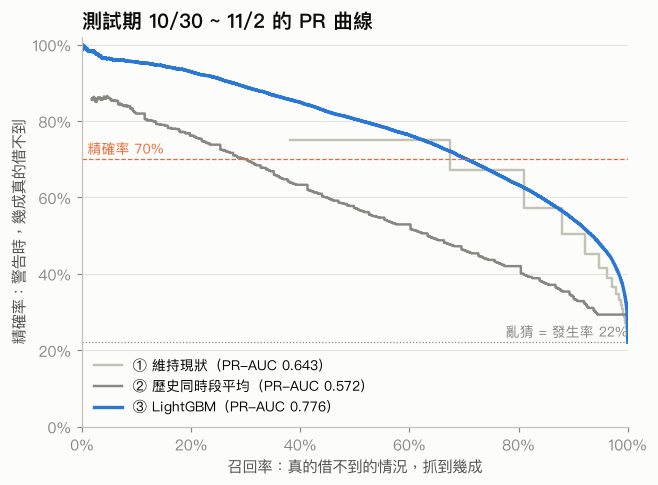

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for name, col in (("① 維持現狀", "score_persist"), ("② 歷史同時段平均", "score_hist"), ("③ LightGBM", "score_lgbm")):
    p, r = _pr_points(test_pred["y"], test_pred[col])
    ap = average_precision(test_pred["y"], test_pred[col])
    ax.plot(r, p, color=MODEL_COLORS[name], lw=2.2 if "LightGBM" in name else 1.6,
            drawstyle="steps-post", label=f"{name}（PR-AUC {ap:.3f}）")
base = test_pred["y"].mean()
ax.axhline(base, color=MUTED, lw=0.8, ls=":")
ax.text(1.0, base + 0.015, f"亂猜 = 發生率 {base:.0%}", color=MUTED, ha="right", fontsize=9)
ax.axhline(0.7, color=C_HIGHLIGHT, lw=0.8, ls="--")
ax.text(0.01, 0.715, "精確率 70%", color=C_HIGHLIGHT, fontsize=9)
ax.set(xlabel="召回率：真的借不到的情況，抓到幾成", ylabel="精確率：警告時，幾成真的借不到",
       xlim=(0, 1), ylim=(0, 1.02), title="測試期 10/30 ~ 11/2 的 PR 曲線")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(loc="lower left", fontsize=9)
plt.show()

**怎麼讀這張圖**：曲線越往右上越好。在「精確率 70%」那條線上（說會沒車時，10 次至少對 7 次），
LightGBM 能抓到約 7 成的借不到；「維持現狀」只能抓到不到 4 成 ——
因為它只會說「現在沒車的站等一下也沒車」，對「現在還有車、等一下會被借光」完全沒有辦法。

另外兩個健全性檢查（程式在 3-7 做過）：
- **把答案打亂再訓練**，測試 PR-AUC 掉到 0.220（= 發生率 0.221）—— 模型沒有其他管道偷看到答案
- 訓練 0.831 → 驗證 0.793 → 測試 0.776：差距小，沒有嚴重的背答案；換 3 個隨機種子，測試 PR-AUC 0.772 ~ 0.776

## 3-8：換三段不同的測試期

只看一段測試期，可能剛好切到「好猜的幾天」。每一段都只用它之前的資料訓練：

- **A**：訓練只有 9/30 ~ 10/7（8 天），測試 10/10 ~ 13（國慶連假 + 10/13 少車那週開始）
- **B**：測試 10/16 ~ 19（10/13 那週全市少約 9% 的車）
- **C**：測試 10/30 ~ 11/2（收集中斷之後，就是上面那張成績單）

In [5]:
fold_rows = []
fold_models = {}
for fold, (v, t) in FOLDS.items():
    r, m, _ = run_period(X, v, t, FEATURES, verbose=False)
    fold_models[fold] = m
    fold_rows += [{"段": fold, **x} for x in r if x["資料"] == "測試"]
folds = pd.DataFrame(fold_rows)

for metric in ("PR-AUC", "recall@P70"):
    wide = folds.pivot_table(index=["時段", "模型"], columns="段", values=metric, sort=False)
    wide["平均"] = wide.mean(axis=1)
    print(f"【{metric}】")
    display(wide.style.format("{:.3f}"))

【PR-AUC】


【recall@P70】


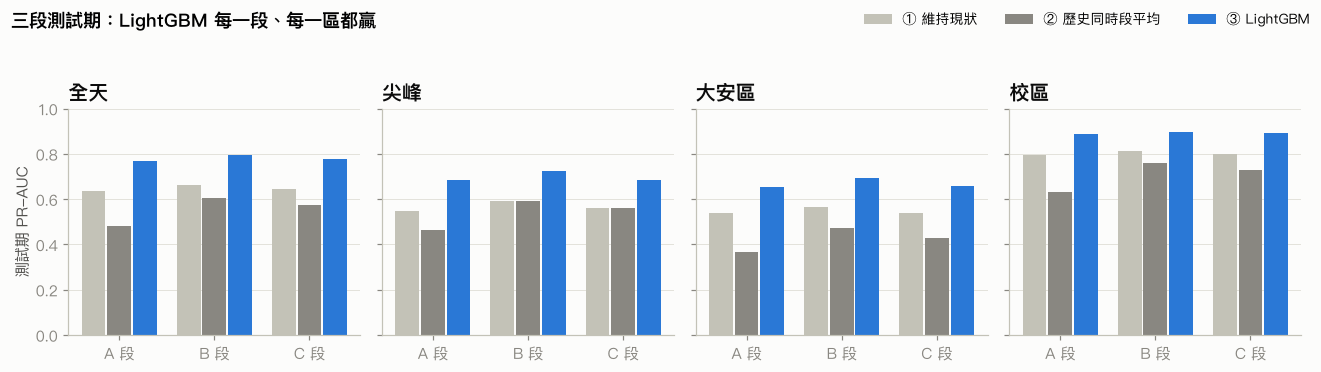

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
models = list(MODEL_COLORS)
for ax, subset in zip(axes, ["全天", "尖峰", "大安區", "校區"]):
    sub = folds[folds["時段"] == subset]
    x = np.arange(len(FOLDS))
    for i, mname in enumerate(models):
        vals = sub[sub["模型"] == mname].set_index("段").loc[list(FOLDS), "PR-AUC"]
        ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=MODEL_COLORS[mname], label=mname)
    ax.set_xticks(x, [f"{f} 段" for f in FOLDS]); ax.set_title(subset); ax.set_ylim(0, 1)
axes[0].set_ylabel("測試期 PR-AUC")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, fontsize=9)
fig.suptitle("三段測試期：LightGBM 每一段、每一區都贏", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

**結論**：三段的結果非常一致，LightGBM 在**每一段、每一個子集合、每一個指標**都贏 ——
連訓練資料只有 8 天的 A 段也是。所以 3-7 的成績不是「剛好切到好猜的日子」。

**定案固定精確率的指標用 recall@P70**（2-6 留下的待決事項）：
- P80：「維持現狀」在每一段都是 0，大安區連模型也只有約 0.2 —— 太嚴，比不出差異
- P60：校區的 baseline 已經 0.95，差異被壓扁
- P70：三個模型拉得開，也對應「說會沒車時 10 次至少對 7 次」的實際意義

## 3-9a：它靠什麼贏？

兩種看法：
1. **特徵重要度（gain）**：每個特徵在所有樹裡總共讓預測進步了多少。
2. **拿掉一組特徵重新訓練**（`scripts/ablation.py`，三段測試期各訓練一次，約 5 分鐘）：
   分數掉多少，才是這組特徵**不可取代**的貢獻。重要度高的特徵如果有替代品，拿掉後分數幾乎不變。

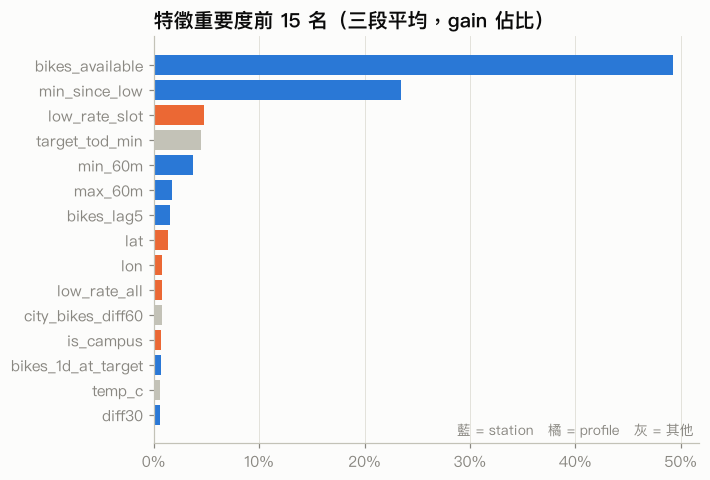

各組加總： {'station': '83.6%', 'profile': '8.8%', 'calendar': '4.9%', 'citywide': '2.0%', 'weather': '0.7%'}


In [7]:
imp = pd.concat({f: feature_importance(m, FEATURES) for f, m in fold_models.items()}, axis=1).mean(axis=1)
imp = imp.sort_values(ascending=False)
group_of = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.barh(top.index, top.values, color=[C_MAIN if group_of[c] == "station" else C_HIGHLIGHT if group_of[c] == "profile" else C_REST for c in top.index])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.set_title("特徵重要度前 15 名（三段平均，gain 佔比）")
ax.text(0.99, 0.02, "藍 = station　橘 = profile　灰 = 其他", transform=ax.transAxes, ha="right", color=MUTED, fontsize=9)
plt.show()
print("各組加總：", imp.groupby(group_of).sum().sort_values(ascending=False).map("{:.1%}".format).to_dict())

In [8]:
abl = pd.read_csv(os.path.join(MODEL_DIR, "ablation_le1.csv"))
summary = abl.groupby(["設定", "時段"], sort=False)["PR-AUC"].mean().unstack("時段")[["全天", "尖峰", "大安區", "校區"]]
full = summary.loc["全部特徵"]
delta = (summary - full).drop(index="全部特徵")
print("三段平均的測試 PR-AUC，以及跟「全部特徵」相比的變化：")
display(summary.style.format("{:.3f}"))
display(delta.style.format("{:+.3f}").background_gradient(cmap="Oranges_r", vmin=-0.05, vmax=0))

三段平均的測試 PR-AUC，以及跟「全部特徵」相比的變化：


時段,全天,尖峰,大安區,校區
設定,,,,
全部特徵,0.780,0.697,0.668,0.893
拿掉 station,0.613,0.599,0.472,0.772
拿掉 calendar,0.771,0.691,0.658,0.885
拿掉 profile,0.764,0.660,0.647,0.886
拿掉 citywide,0.781,0.699,0.669,0.894
拿掉 weather,0.781,0.698,0.670,0.894
只有 station,0.747,0.647,0.632,0.863


時段,全天,尖峰,大安區,校區
設定,,,,
拿掉 station,-0.167,-0.098,-0.196,-0.121
拿掉 calendar,-0.008,-0.006,-0.010,-0.009
拿掉 profile,-0.016,-0.037,-0.021,-0.007
拿掉 citywide,+0.001,+0.001,+0.001,+0.001
拿掉 weather,+0.001,+0.001,+0.002,+0.001
只有 station,-0.033,-0.050,-0.036,-0.030


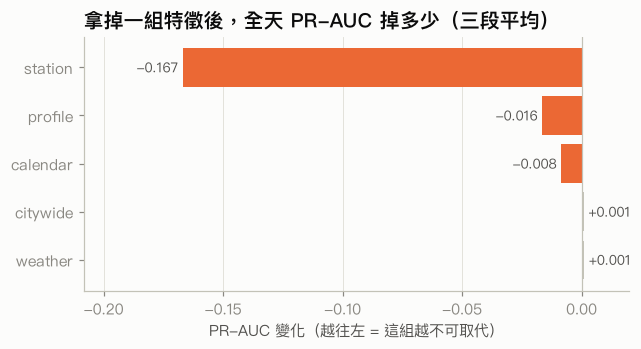

In [9]:
drop = delta.loc[[i for i in delta.index if i.startswith("拿掉")], "全天"].sort_values()
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.barh([i.replace("拿掉 ", "") for i in drop.index][::-1], drop.values[::-1],
        color=[C_HIGHLIGHT if v < -0.005 else C_REST for v in drop.values[::-1]])
ax.axvline(0, color=AXIS, lw=0.8)
for y, v in enumerate(drop.values[::-1]):
    ax.text(v - 0.002 if v < 0 else v + 0.002, y, f"{v:+.3f}", va="center", ha="right" if v < 0 else "left",
            color=INK2, fontsize=9)
ax.set_xlim(drop.min() * 1.25, 0.02)
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.set_title("拿掉一組特徵後，全天 PR-AUC 掉多少（三段平均）")
ax.set_xlabel("PR-AUC 變化（越往左 = 這組越不可取代）")
plt.show()

## 3-9b：它哪裡還會猜錯？

用 C 段（測試 10/30 ~ 11/2）的預測來看。

In [10]:
d = test_pred.copy()
M = {"① 維持現狀": "score_persist", "② 歷史同時段平均": "score_hist", "③ LightGBM": "score_lgbm"}

def aps(x):
    return {k: round(average_precision(x["y"], x[v]), 3) for k, v in M.items()}

now_ok = d[d["bikes_available"] >= 2]
now_low = d[d["bikes_available"] <= 1]
print(f"全部借不到的情況裡，{now_ok['y'].sum() / d['y'].sum():.1%} 是「現在還有 >= 2 台」—— 突然被借光")
print("  現在 >= 2 台的樣本，PR-AUC：", aps(now_ok))
print(f"現在 <= 1 台的樣本，30 分鐘後仍 <= 1 的比例 {now_low['y'].mean():.1%}，PR-AUC：", aps(now_low))

全部借不到的情況裡，32.5% 是「現在還有 >= 2 台」—— 突然被借光
  現在 >= 2 台的樣本，PR-AUC： {'① 維持現狀': 0.269, '② 歷史同時段平均': 0.24, '③ LightGBM': 0.434}
現在 <= 1 台的樣本，30 分鐘後仍 <= 1 的比例 67.3%，PR-AUC： {'① 維持現狀': 0.716, '② 歷史同時段平均': 0.826, '③ LightGBM': 0.864}


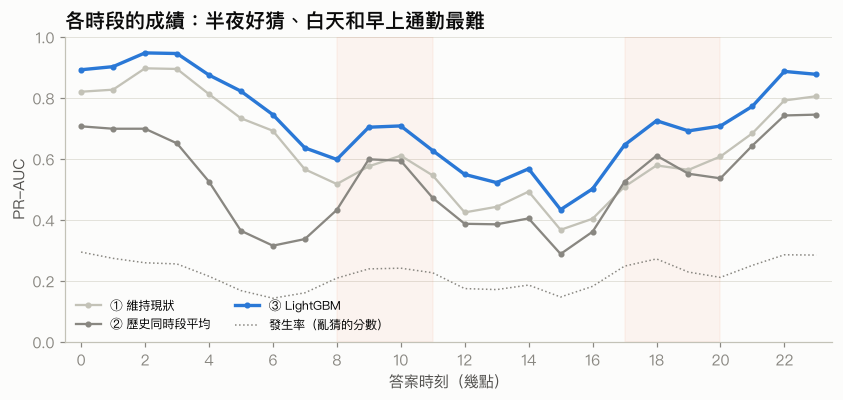

In [11]:
by_hour = d.groupby("target_hour").apply(
    lambda x: pd.Series({k: average_precision(x["y"], x[v]) for k, v in M.items()} | {"發生率": x["y"].mean()}),
    include_groups=False)
fig, ax = plt.subplots(figsize=(9, 3.6))
for name in M:
    ax.plot(by_hour.index, by_hour[name], color=MODEL_COLORS[name], lw=2.2 if "LightGBM" in name else 1.5, marker="o", ms=3, label=name)
ax.plot(by_hour.index, by_hour["發生率"], color=MUTED, lw=1, ls=":", label="發生率（亂猜的分數）")
ax.axvspan(8, 11, color=C_HIGHLIGHT, alpha=0.06); ax.axvspan(17, 20, color=C_HIGHLIGHT, alpha=0.06)
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5); ax.set_ylim(0, 1)
ax.set(xlabel="答案時刻（幾點）", ylabel="PR-AUC", title="各時段的成績：半夜好猜、白天和早上通勤最難")
ax.legend(loc="lower left", fontsize=8, ncol=2)
plt.show()

In [12]:
# 選出「精確率 70%」的警告門檻，看看猜錯的是哪些情況
order = np.argsort(-d["score_lgbm"].to_numpy(), kind="mergesort")
ys, ss = d["y"].to_numpy()[order], d["score_lgbm"].to_numpy()[order]
prec = np.cumsum(ys) / np.arange(1, len(ys) + 1)
thr = ss[np.where(prec >= 0.7)[0].max()]
d["alert"] = d["score_lgbm"] >= thr
fp, fn = d[d["alert"] & ~d["y"]], d[~d["alert"] & d["y"]]
print(f"精確率 70% 的警告門檻：風險分數 >= {thr:.3f}（會對 {d['alert'].mean():.1%} 的時刻發出警告）")
print(f"誤報（說會沒車、其實有）{len(fp):,} 筆，其中 30 分鐘後剛好 2 台（差一台就猜對）的佔 {(fp['bikes_future'] == 2).mean():.0%}")
print(f"漏報（沒警告、借不到）{len(fn):,} 筆，其中現在還有 >= 5 台的佔 {(fn['bikes_available'] >= 5).mean():.0%}")

big = fn[fn["bikes_available"] >= 5]
names = load_stations().set_index("station_id")["name"].str.replace("YouBike2.0_", "")
print(f"「現在 >= 5 台、30 分鐘內被借光」的漏報：平均 30 分鐘少了 {(big['bikes_available'] - big['bikes_future']).mean():.1f} 台")
print("  最常發生的站：", names.loc[big["station_id"]].value_counts().head(6).to_dict())

精確率 70% 的警告門檻：風險分數 >= 0.429（會對 22.3% 的時刻發出警告）
誤報（說會沒車、其實有）21,153 筆，其中 30 分鐘後剛好 2 台（差一台就猜對）的佔 44%
漏報（沒警告、借不到）20,642 筆，其中現在還有 >= 5 台的佔 24%


「現在 >= 5 台、30 分鐘內被借光」的漏報：平均 30 分鐘少了 7.3 台
  最常發生的站： {'捷運大安站(5號出口)': 53, '捷運大安站(4號出口)': 46, '信義大安路口(信維大樓)': 45, '信義敦化路口': 45, '羅斯福路三段311號前': 42, '復興南路二段128巷口': 41}


In [13]:
# 每一站分開看：有沒有哪些站模型反而輸給「維持現狀」
def per_station(x):
    enough = x["y"].sum() >= 20          # 4 天裡借不到少於 20 次的站，分數太不穩，不算
    return pd.Series({"lgbm": average_precision(x["y"], x["score_lgbm"]) if enough else np.nan,
                      "persist": average_precision(x["y"], x["score_persist"]) if enough else np.nan})
st = d.groupby("station_id").apply(per_station, include_groups=False).dropna()
lose = st[st["lgbm"] < st["persist"]]
print(f"{len(st)} 站裡，LightGBM 贏 {len(st) - len(lose)} 站、輸 {len(lose)} 站；"
      f"每站 PR-AUC 中位數 {st['lgbm'].median():.3f}（維持現狀 {st['persist'].median():.3f}）")
print(f"輸的站差距中位數只有 {(lose['lgbm'] - lose['persist']).median():.3f}，最多 {(lose['lgbm'] - lose['persist']).min():.3f}")

275 站裡，LightGBM 贏 261 站、輸 14 站；每站 PR-AUC 中位數 0.619（維持現狀 0.541）
輸的站差距中位數只有 -0.012，最多 -0.050


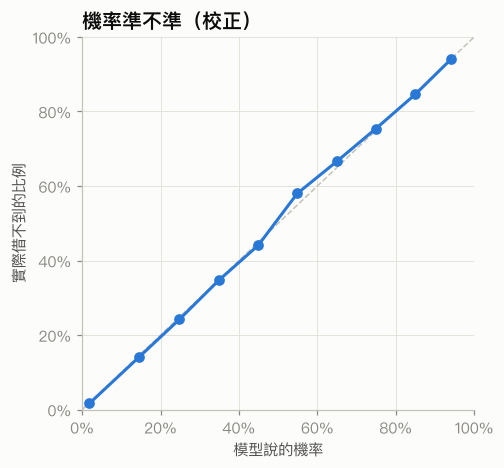

In [14]:
d["bin"] = pd.cut(d["score_lgbm"], np.linspace(0, 1, 11), include_lowest=True)
cal = d.groupby("bin", observed=True).agg(n=("y", "size"), 預測=("score_lgbm", "mean"), 實際=("y", "mean"))
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
ax.plot(cal["預測"], cal["實際"], color=C_MAIN, marker="o", lw=2)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="模型說的機率", ylabel="實際借不到的比例", title="機率準不準（校正）")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(axis="x", color=GRID)
plt.show()

## 3-9 結論

**1. 模型主要靠「這一站自己」贏。**
station 組（現在幾台、距離上次快沒車多久、最近一小時的變化）是主力：拿掉它 PR-AUC 掉 0.17，
只用它一組就有 0.747（baseline 最好 0.648）。重要度前兩名是「現在幾台」和「距離上次 <= 1 台幾分鐘」——
正是 EDA 說的「剛空過的站最容易再空」。

**2. 站的類型對尖峰很重要，日曆有小幫助。**
拿掉 profile（過去這個時段多容易空、是不是校區、位置），全天只掉 0.016，但**尖峰的 recall@P70 掉了約 0.10**：
尖峰正是「平常這時段會不會被借光」最有用的時候。拿掉 calendar 掉 0.008。

**3. 全市總數、天氣目前沒有幫助（拿掉反而 +0.001）——如實記錄。**
推測原因：全市狀態的變化（例如 10/13 那週少車）已經反映在每一站自己的車數和歷史比例裡；
下雨（60 分鐘 > 0.5 mm）的樣本只有 2.8%，四週裡雨天太少，學不到。
它們不會讓模型變差，所以先保留；資料滿 2 ~ 3 個月、雨天變多之後重做這個實驗再決定。

**4. 還會猜錯的地方。**
- **突然被借光**：32.5% 的「借不到」發生在「現在還有 >= 2 台」的時候，這部分模型 PR-AUC 只有 0.43（baseline 0.27）。
  其中「現在 >= 5 台、30 分鐘內少了 7 台以上」的漏報，集中在捷運大安站、信義大安路口等通勤站。
  檢查過 99% 是真的被借走（空位跟著增加、總車柱數不變），不是資料錯誤。
- **時段**：半夜最好猜（空了就一直空，PR-AUC 0.9 左右），**中午到下午**和**早上 7 ~ 8 點**最難。
- **誤報裡 44% 是 30 分鐘後剛好 2 台**——差一台就猜對了；對使用者來說「只剩 2 台」本來就有風險，這種誤報代價不大。
- 少數站（約 5%）模型略輸給維持現狀，但差距都很小（中位數約 0.01）。

**5. 機率很準（校正良好）**：模型說 30%，實際就約 30%。上線時可以直接顯示「30 分鐘後借不到的機率」。

**下一輪可以補的特徵**（phase 3 之後再做）：
- **附近站的狀態**：旁邊幾站都空了，借車的人就會湧到這一站（最可能改善「突然被借光」）
- **捷運的人流**：大安站、信義安和的漏報集中在通勤時段，跟捷運進出站量可能有關
- **臺大的行事曆**（考試週、校慶）：校區的節奏跟學期有關
- 資料變多之後，重新驗證全市總數和天氣